In [1]:

!pip install -q ucimlrepo


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Fetch the official UCI dataset
credit_data = fetch_ucirepo(id=350)

# Separate input features and target
X = credit_data.data.features
y = credit_data.data.targets

# Combine them for initial inspection
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget column:")
print(y.columns.tolist())


Column names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int

Target distribution:
Y
0    23364
1     6636
Name: count, dtype: int64

Target percentage:
Y
0    77.88
1    22.12
Name: proportion, dtype: float64


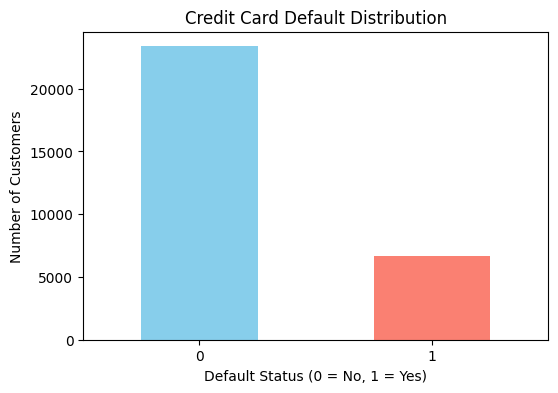

In [4]:
print("Target distribution:")
print(df["Y"].value_counts())

print("\nTarget percentage:")
print(df["Y"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
df["Y"].value_counts().sort_index().plot(
    kind="bar",
    color=["skyblue", "salmon"]
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Y"])
y = df["Y"]

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (24000, 23)
Testing features: (6000, 23)

Training target distribution:
Y
0    77.879167
1    22.120833
Name: proportion, dtype: float64

Testing target distribution:
Y
0    77.883333
1    22.116667
Name: proportion, dtype: float64


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Replace only the Logistic Regression model
models["Logistic Regression"] = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000)
)

# Train it again
models["Logistic Regression"].fit(X_train, y_train)

print("Logistic Regression retrained successfully!")

Logistic Regression retrained successfully!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for name, model in models.items():
    # Predict class labels
    y_pred = model.predict(X_test)

    # Predict probability of default (class 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("Credit Scoring Model Evaluation:")
display(results_df.round(4))


Credit Scoring Model Evaluation:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8077,0.6868,0.2396,0.3553,0.7076
1,Decision Tree,0.8158,0.6476,0.3670,0.4685,0.7458
2,Random Forest,0.8170,0.6615,0.3534,0.4607,0.7727


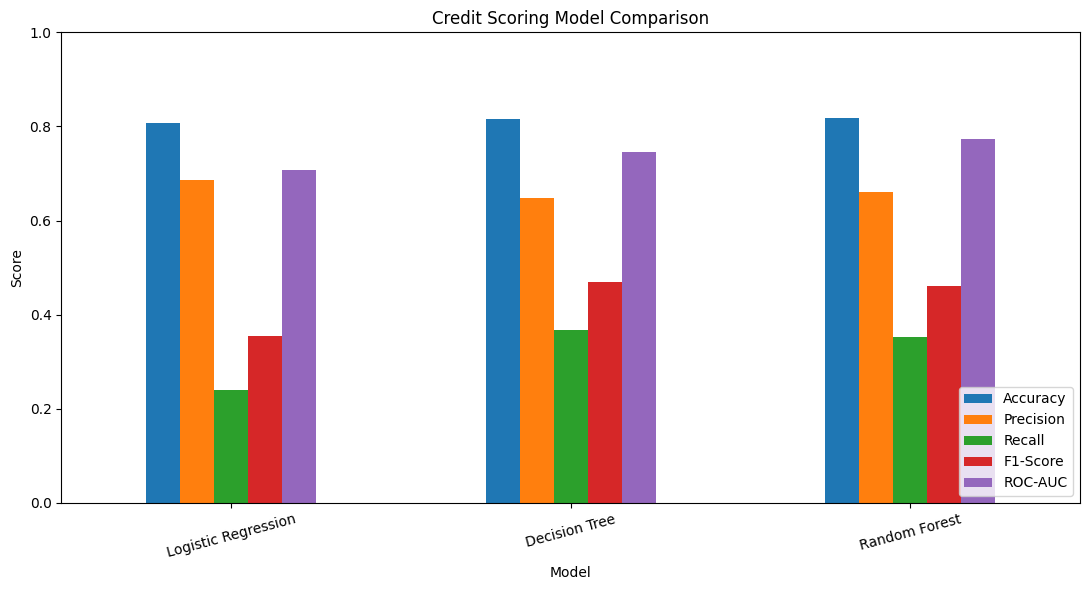

In [9]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Credit Scoring Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Train a balanced Random Forest model
balanced_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

balanced_rf.fit(X_train, y_train)

# Make predictions
y_pred_balanced = balanced_rf.predict(X_test)
y_prob_balanced = balanced_rf.predict_proba(X_test)[:, 1]

print("Balanced Random Forest Results:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["No Default", "Default"]
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_balanced), 4
))

Balanced Random Forest Results:
              precision    recall  f1-score   support

  No Default       0.87      0.87      0.87      4673
     Default       0.54      0.53      0.54      1327

    accuracy                           0.80      6000
   macro avg       0.70      0.70      0.70      6000
weighted avg       0.79      0.80      0.80      6000

ROC-AUC: 0.7702


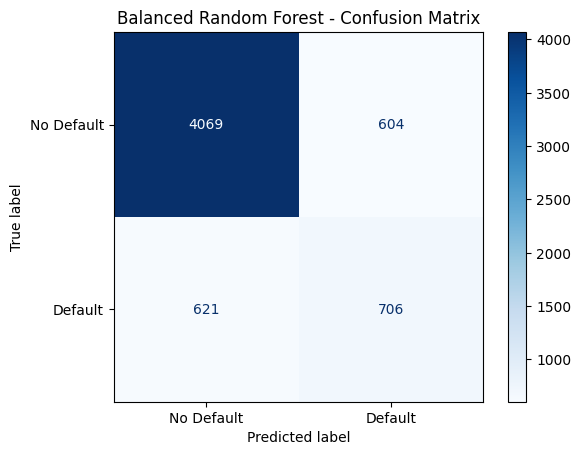

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Balanced Random Forest - Confusion Matrix")
plt.show()

In [12]:
import joblib

# Save the balanced Random Forest model
joblib.dump(balanced_rf, "credit_scoring_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [13]:
import joblib

# Load the saved model
loaded_model = joblib.load("credit_scoring_model.pkl")

# Predict one customer from the test data
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0][1]

print("Predicted default status:", prediction)
print("Probability of default:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Prediction: Customer is classified as likely to default.")
else:
    print("Prediction: Customer is classified as not likely to default.")

Predicted default status: 0
Probability of default: 27.28 %
Prediction: Customer is classified as not likely to default.


In [14]:
readme_content = """
# Credit Scoring Model

## Project Overview
This project uses machine learning to predict credit card payment default
based on customer financial and repayment information.

## Dataset
- Source: UCI Machine Learning Repository
- Dataset: Default of Credit Card Clients
- Records: 30,000
- Input features: 23
- Target: Y (0 = No Default, 1 = Default)

## Models Used
- Logistic Regression
- Decision Tree
- Random Forest
- Balanced Random Forest

## Evaluation
The models were evaluated using:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

The balanced Random Forest achieved approximately 53% recall
for the default class and an ROC-AUC of 0.7702.

## Files
- credit_scoring.ipynb: Project notebook
- credit_scoring_model.pkl: Saved balanced Random Forest model
- requirements.txt: Required Python libraries

## Disclaimer
This is an educational machine learning project, not a
professional credit assessment or financial decision system.
"""

requirements_content = """
pandas
numpy
matplotlib
scikit-learn
joblib
ucimlrepo
"""

with open("README.md", "w") as f:
    f.write(readme_content.strip() + "\n")

with open("requirements.txt", "w") as f:
    f.write(requirements_content.strip() + "\n")

print("README.md created successfully!")
print("requirements.txt created successfully!")

README.md created successfully!
requirements.txt created successfully!
